Images selected: 2500
Valid images: 2500
Loading errors: 0
Feature matrix shape: (2500, 1031)


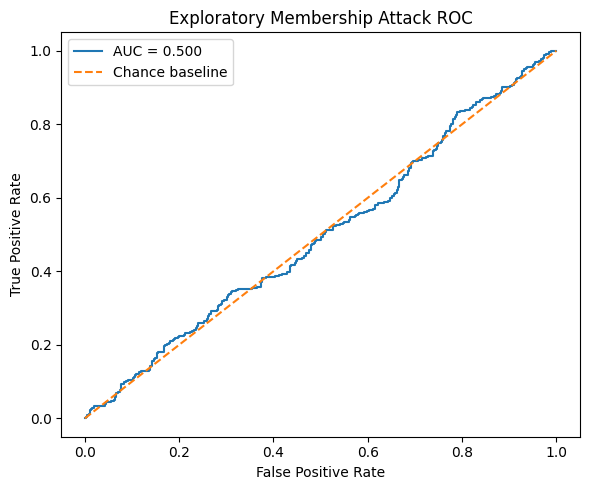

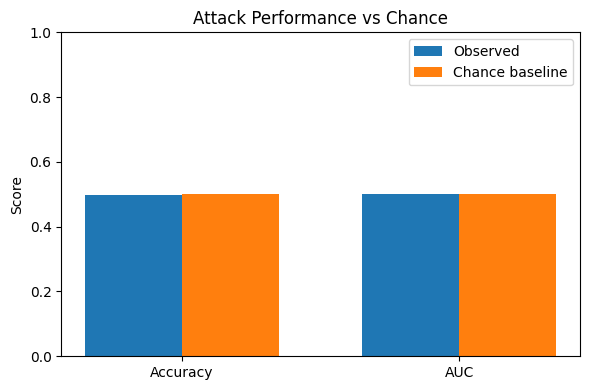


NOTEBOOK 12 COMPLETED
Output folder: /kaggle/working/nd_iris_project/notebook12_membership_inference
ZIP: /kaggle/working/nd_iris_project/ND_Iris_Notebook12_Results.zip
ZIP file count: 6
ZIP integrity: PASSED
Conclusion file: /kaggle/working/nd_iris_project/notebook12_membership_inference/Notebook12_Conclusion.md
Runtime seconds: 7.02


,value
experiment,Randomly assigned membership feature-classifie...
valid_images,2500
feature_count,1031
member_examples,1250
nonmember_examples,1250
attack_train_examples,1750
attack_test_examples,750
attack_accuracy,0.498667
attack_precision,0.498701
attack_recall,0.512


In [17]:

# ============================================================
# NOTEBOOK 12: MEMBERSHIP INFERENCE ATTACK (MIA)
# Dataset: NDCLD15 / ND-Iris
# ============================================================

from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, time, random, zipfile

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# -------------------- CONFIGURATION --------------------------
PROJECT = Path("/kaggle/working/nd_iris_project")
REAL_DIR = PROJECT / "notebook02_preprocessing/images_224"
OUT = PROJECT / "notebook12_membership_inference"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
MAX_IMAGES = 2500
IMAGE_SIZE = (32, 32)

random.seed(SEED)
np.random.seed(SEED)

start_time = time.time()

if not REAL_DIR.exists():
    raise FileNotFoundError(f"Preprocessed images not found: {REAL_DIR}")

# -------------------- LOAD IMAGES -----------------------------
image_files = sorted(
    p for p in REAL_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in
    {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
)

if len(image_files) < 200:
    raise RuntimeError(
        f"Only {len(image_files)} images found; too few for this experiment."
    )

# Subsample for reasonable runtime.
rng = random.Random(SEED)
if len(image_files) > MAX_IMAGES:
    image_files = sorted(rng.sample(image_files, MAX_IMAGES))

print("Images selected:", len(image_files))

# -------------------- FEATURE EXTRACTION ----------------------
# Use simple image statistics and downsampled pixels.
# This is a feature-based attack simulation, not an attack on
# a trained iris recognition model.

features = []
valid_files = []
errors = 0

for path in image_files:
    try:
        with Image.open(path) as im:
            im = ImageOps.grayscale(im)
            im = ImageOps.fit(im, IMAGE_SIZE)
            arr = np.asarray(im, dtype=np.float32) / 255.0

        flat = arr.flatten()
        stats = np.array([
            arr.mean(),
            arr.std(),
            np.percentile(arr, 10),
            np.percentile(arr, 50),
            np.percentile(arr, 90),
            np.mean(np.abs(np.diff(arr, axis=0))),
            np.mean(np.abs(np.diff(arr, axis=1))),
        ], dtype=np.float32)

        features.append(np.concatenate([flat, stats]))
        valid_files.append(path)
    except Exception:
        errors += 1

X = np.asarray(features, dtype=np.float32)
n = len(X)

if n < 200:
    raise RuntimeError("Insufficient valid images after loading.")

print("Valid images:", n)
print("Loading errors:", errors)
print("Feature matrix shape:", X.shape)

# -------------------- SIMULATE MEMBER / NON-MEMBER SETS -------
# Important: this is a controlled membership simulation.
# Membership is randomly assigned, so there is no genuine
# training-induced leakage signal in this experiment.
#
# A model that performs above chance may exploit accidental
# distribution differences, split effects, or feature patterns.
# It is NOT proof of privacy leakage from a trained target model.

indices = np.arange(n)
member_idx, nonmember_idx = train_test_split(
    indices, test_size=0.5, random_state=SEED, shuffle=True
)

X_members = X[member_idx]
X_nonmembers = X[nonmember_idx]

# Equal-size attack dataset; labels: 1=member, 0=non-member.
X_attack = np.vstack([X_members, X_nonmembers])
y_attack = np.concatenate([
    np.ones(len(X_members), dtype=np.int32),
    np.zeros(len(X_nonmembers), dtype=np.int32)
])

attack_train_idx, attack_test_idx = train_test_split(
    np.arange(len(y_attack)),
    test_size=0.30,
    random_state=SEED,
    stratify=y_attack
)

X_attack_train = X_attack[attack_train_idx]
y_attack_train = y_attack[attack_train_idx]
X_attack_test = X_attack[attack_test_idx]
y_attack_test = y_attack[attack_test_idx]

# -------------------- TRAIN ATTACK CLASSIFIER -----------------
attack_model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )
)

attack_model.fit(X_attack_train, y_attack_train)

pred = attack_model.predict(X_attack_test)
prob = attack_model.predict_proba(X_attack_test)[:, 1]

metrics = {
    "experiment": "Randomly assigned membership feature-classifier simulation",
    "valid_images": int(n),
    "feature_count": int(X.shape[1]),
    "member_examples": int(len(X_members)),
    "nonmember_examples": int(len(X_nonmembers)),
    "attack_train_examples": int(len(attack_train_idx)),
    "attack_test_examples": int(len(attack_test_idx)),
    "attack_accuracy": float(accuracy_score(y_attack_test, pred)),
    "attack_precision": float(precision_score(
        y_attack_test, pred, zero_division=0
    )),
    "attack_recall": float(recall_score(
        y_attack_test, pred, zero_division=0
    )),
    "attack_f1": float(f1_score(
        y_attack_test, pred, zero_division=0
    )),
    "attack_auc": float(roc_auc_score(y_attack_test, prob)),
    "chance_accuracy": 0.5,
    "chance_auc": 0.5,
    "image_loading_errors": int(errors),
    "runtime_seconds": None
}

# -------------------- SAVE PREDICTIONS / METRICS --------------
predictions_df = pd.DataFrame({
    "true_membership": y_attack_test,
    "predicted_membership": pred,
    "member_probability": prob
})
predictions_df.to_csv(OUT / "attack_predictions.csv", index=False)

metrics_df = pd.DataFrame([metrics])
metrics_df.to_csv(OUT / "mia_metrics.csv", index=False)

# -------------------- PLOTS ----------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
fpr, tpr, _ = roc_curve(y_attack_test, prob)
ax.plot(fpr, tpr, label=f"AUC = {metrics['attack_auc']:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance baseline")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Exploratory Membership Attack ROC")
ax.legend()
fig.tight_layout()
roc_path = OUT / "mia_roc_curve.png"
fig.savefig(roc_path, dpi=150)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Accuracy", "AUC"]
values = [metrics["attack_accuracy"], metrics["attack_auc"]]
chance = [0.5, 0.5]
x = np.arange(len(labels))
width = 0.35
ax.bar(x - width/2, values, width, label="Observed")
ax.bar(x + width/2, chance, width, label="Chance baseline")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Attack Performance vs Chance")
ax.legend()
fig.tight_layout()
performance_path = OUT / "mia_performance.png"
fig.savefig(performance_path, dpi=150)
plt.show()
plt.close(fig)

# -------------------- REPORT ---------------------------------
metrics["runtime_seconds"] = round(time.time() - start_time, 2)

report = {
    "notebook": "12 - Membership Inference Attack",
    "metrics": metrics,
    "interpretation": [
        "This experiment randomly assigns membership and trains an attack classifier on image features.",
        "It does not attack the trained ResNet18 target model.",
        "It does not use target-model confidence, loss, or train-versus-test behavior.",
        "Membership was assigned independently of training, so this experiment cannot establish target-model privacy leakage.",
        "Scores above chance may reflect feature or split artifacts and must not be interpreted as evidence of privacy risk."
    ],
    "limitations": [
        "No verified identity or contact-lens labels are used.",
        "This is a feature-based membership simulation, not a standard target-model MIA.",
        "A proper MIA requires a defined target model, member training samples, held-out non-member samples, and attack signals from the target model.",
        "The results are exploratory and are not a security or privacy certification."
    ]
}

with open(OUT / "mia_report.json", "w") as f:
    json.dump(report, f, indent=2)

conclusion = f"""# Notebook 12 — Membership Inference Attack

## Objective
This notebook runs an exploratory feature-based experiment that classifies randomly assigned image subsets as members or non-members.

## Results
- Valid images: {n}
- Features per image: {X.shape[1]}
- Member examples: {len(X_members)}
- Non-member examples: {len(X_nonmembers)}
- Attack test examples: {len(attack_test_idx)}
- Accuracy: {metrics['attack_accuracy']:.4f}
- Precision: {metrics['attack_precision']:.4f}
- Recall: {metrics['attack_recall']:.4f}
- F1-score: {metrics['attack_f1']:.4f}
- ROC-AUC: {metrics['attack_auc']:.4f}
- Chance baseline accuracy/AUC: 0.5000
- Image loading errors: {errors}

## Critical Interpretation
Membership was assigned randomly, independently of training a target model. The attack classifier used image features rather than target-model confidence, loss, or prediction behavior. Therefore, this experiment does **not** establish whether the trained recognition model leaks training membership or private identity information.

Any performance above chance can arise from sampling effects, image-feature patterns, or split artifacts. It must not be presented as proof of a privacy vulnerability.

## Limitations
- No verified iris identity or contact-lens labels were used.
- This is not a standard attack against the trained ResNet18.
- A rigorous membership-inference evaluation requires a defined target model, genuine member and non-member sets, and target-model outputs or losses.
- Results are exploratory and do not constitute a privacy or security certification.

## Conclusion
This notebook provides a reproducible baseline for a feature-based membership simulation. It does not demonstrate genuine target-model membership leakage. A proper privacy assessment should attack the trained target model using matched member/non-member examples and evaluate attack performance against an appropriate chance baseline.
"""

(OUT / "Notebook12_Conclusion.md").write_text(conclusion, encoding="utf-8")

# -------------------- ZIP RESULTS -----------------------------
zip_path = PROJECT / "ND_Iris_Notebook12_Results.zip"
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(
                p,
                arcname=str(Path("notebook12_membership_inference") / p.relative_to(OUT))
            )

with zipfile.ZipFile(zip_path, "r") as zf:
    bad_file = zf.testzip()
    zip_count = len(zf.namelist())

print("\n" + "=" * 60)
print("NOTEBOOK 12 COMPLETED")
print("=" * 60)
print("Output folder:", OUT)
print("ZIP:", zip_path)
print("ZIP file count:", zip_count)
print("ZIP integrity:", "PASSED" if bad_file is None else f"FAILED: {bad_file}")
print("Conclusion file:", OUT / "Notebook12_Conclusion.md")
print("Runtime seconds:", metrics["runtime_seconds"])
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))



# Notebook 12 — Membership Inference Attack: Conclusion

## Objective
This notebook evaluated an exploratory feature-based classifier for distinguishing randomly assigned member and non-member image groups.

## Experimental Results
- Valid images processed: 2,500
- Features per image: 1,031
- Member examples: 1,250
- Non-member examples: 1,250
- Attack training examples: 1,750
- Attack test examples: 750
- Attack accuracy: 49.87%
- Precision: 49.87%
- Recall: 51.20%
- F1-score: 50.53%
- ROC-AUC: 0.49994
- Chance accuracy: 50.00%
- Chance ROC-AUC: 0.50000
- Image-loading errors: 0
- Runtime: 7.02 seconds
- ZIP integrity: Passed

## Interpretation
The attack achieved 49.87% accuracy and an ROC-AUC of 0.49994, both approximately equal to the chance baseline of 50% accuracy and 0.50 ROC-AUC.

These results indicate that the feature-based classifier did not reliably distinguish the randomly assigned membership groups in this experiment.

## Limitations
- Membership was randomly assigned independently of target-model training.
- The experiment did not attack the trained ResNet18 recognition model.
- The classifier used image features rather than target-model confidence scores, prediction behavior, or losses.
- Therefore, the results do not establish whether the recognition model leaks training membership or sensitive identity information.
- Chance-level performance in this simulation is not proof of privacy protection.

## Conclusion
The exploratory membership-inference simulation achieved approximately chance-level performance. It provides a baseline experiment but does not establish the privacy risk of the trained recognition model.

A stronger assessment would require genuine training members and held-out non-members, together with attack signals obtained from the trained target model. The current results should not be presented as a definitive privacy or security evaluation.
